In [47]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from collections import OrderedDict
from datasets import load_dataset
from sklearn.metrics import accuracy_score, classification_report
from nltk.util import bigrams
from collections import Counter

import experiment
import clslib
import analysis
import loglin


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [48]:
dataset = load_dataset("stanfordnlp/sst2")
# temp_train_df = dataset["train"].to_pandas()
# temp_val_df = dataset["validation"].to_pandas()
# dataset_df = pd.concat([temp_train_df, temp_val_df], ignore_index=True).drop(columns=['idx'])
# train_df, val_df, test_df = np.split(dataset_df, [int(0.8 * len(dataset_df)), int(0.9 * len(dataset_df))])

# train_dataset = Dataset.from_pandas(train_df)
# val_dataset = Dataset.from_pandas(val_df)
# test_dataset = Dataset.from_pandas(test_df)
train_dataset = dataset["train"]
test_dataset = dataset["validation"]

In [49]:
vocab_size = 1000
top_bigrams_num = 10000
min_frequency = 2
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []
results_folder = Path("./results")
results_folder.mkdir(exist_ok=True)

for seed in my_seeds:
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(train_dataset["sentence"], train_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

bpe_tokenizer = experiment.train_bpe_tokenizer(train_dataset["sentence"], vocab_size, min_frequency)

corpus_bigrams = []
for text in train_dataset["sentence"]:
    tokens = bpe_tokenizer.encode(text).tokens
    corpus_bigrams.extend(bigrams(tokens))

top_bigrams = [item for item, _ in Counter(corpus_bigrams).most_common(top_bigrams_num)]
bigram_encoder = clslib.BagOfBigrams(top_bigrams, bpe_tokenizer)

my_classifiers = OrderedDict()

In [50]:
# test
text = "A good good movie"

print(bpe_tokenizer.encode(text).tokens)
print(len(bigram_encoder))
print(bigram_encoder._vocab[0:3])

['▁', '[UNK]', '▁good', '▁good', '▁movie']
10000
(('▁.', '▁'), ('▁of', '▁the'), ('▁,', '▁and'))


In [51]:
my_classifiers['logistic_bigram-enc'] = []

for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bigram-enc/seed-{seed}"

    my_classifiers['logistic_bigram-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            encoder=bigram_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

C:\Users\PCUser\AppData\Roaming\Python\Python310\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\PCUser\AppData\Roaming\Python\Python310\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\PCUser\AppData\Roaming\Python\Python310\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\PCUser\AppData\Roaming\Python\Python310\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\PCUser\AppData\Roaming\Python\Python310\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


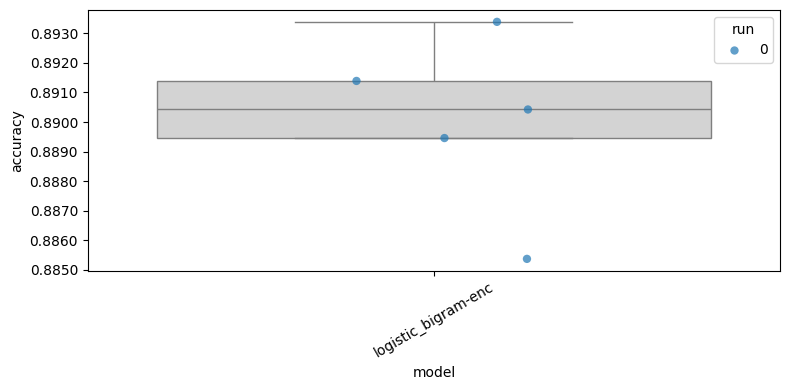

In [52]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

In [53]:
print(my_classifiers['logistic_bigram-enc'][0]['accuracies'])

OrderedDict([(0, 0.891388270230141), (1, 0.8853749072011878), (2, 0.890423162583519), (3, 0.8894580549368968), (4, 0.8933848095626995)])


In [54]:
testing_sentences = test_dataset["sentence"]
testing_labels = test_dataset["label"]

for run, seed in enumerate(my_seeds):
    for fold in range(num_folds):
        model_path = f"{results_folder}/logistic_bigram-enc/seed-{seed}/fold-{fold}/model"

        model = loglin.load(model_path)
        predictions = loglin.predict(
            testing_sentences, model, bigram_encoder
        )

        print(f"Seed {seed}, fold {fold}:")
        print(f"Test accuracy: {accuracy_score(testing_labels, predictions):.4f}")
        print(classification_report(testing_labels, predictions))

Seed 0, fold 0:
Test accuracy: 0.7924
              precision    recall  f1-score   support

           0       0.82      0.75      0.78       428
           1       0.77      0.84      0.80       444

    accuracy                           0.79       872
   macro avg       0.79      0.79      0.79       872
weighted avg       0.79      0.79      0.79       872

Seed 0, fold 1:
Test accuracy: 0.7959
              precision    recall  f1-score   support

           0       0.82      0.75      0.78       428
           1       0.78      0.84      0.81       444

    accuracy                           0.80       872
   macro avg       0.80      0.80      0.80       872
weighted avg       0.80      0.80      0.80       872

Seed 0, fold 2:
Test accuracy: 0.7947
              precision    recall  f1-score   support

           0       0.82      0.75      0.78       428
           1       0.78      0.84      0.81       444

    accuracy                           0.79       872
   macro avg  

In [55]:
# save results
Path("metrics").mkdir(exist_ok=True)

df = analysis.make_data_frame(my_classifiers)
df["seed"] = df["run"].map(dict(enumerate(my_seeds)))

df.to_csv(f"metrics/{next(iter(my_classifiers))}.csv", index=False)